Using device: cpu
Epoch 001 | Train MSE: 26.171723 | Val MSE: 16.043769 | Train MAE: 4.317925 | Val MAE: 3.283928
Epoch 002 | Train MSE: 7.438972 | Val MSE: 4.759570 | Train MAE: 2.087713 | Val MAE: 1.680788
Epoch 003 | Train MSE: 3.308290 | Val MSE: 4.695553 | Train MAE: 1.409305 | Val MAE: 1.659505
Epoch 004 | Train MSE: 2.087301 | Val MSE: 4.224447 | Train MAE: 1.142712 | Val MAE: 1.574716
Epoch 005 | Train MSE: 1.512537 | Val MSE: 4.310719 | Train MAE: 0.963280 | Val MAE: 1.594954
Epoch 006 | Train MSE: 1.171398 | Val MSE: 4.083789 | Train MAE: 0.853857 | Val MAE: 1.547482
Epoch 007 | Train MSE: 0.967026 | Val MSE: 4.084556 | Train MAE: 0.781968 | Val MAE: 1.540126
Epoch 008 | Train MSE: 0.727394 | Val MSE: 4.096380 | Train MAE: 0.673668 | Val MAE: 1.546961
Epoch 009 | Train MSE: 0.562794 | Val MSE: 4.080266 | Train MAE: 0.596822 | Val MAE: 1.542532
Epoch 010 | Train MSE: 0.455614 | Val MSE: 4.021188 | Train MAE: 0.536246 | Val MAE: 1.520239
Epoch 011 | Train MSE: 0.360167 | Val MS

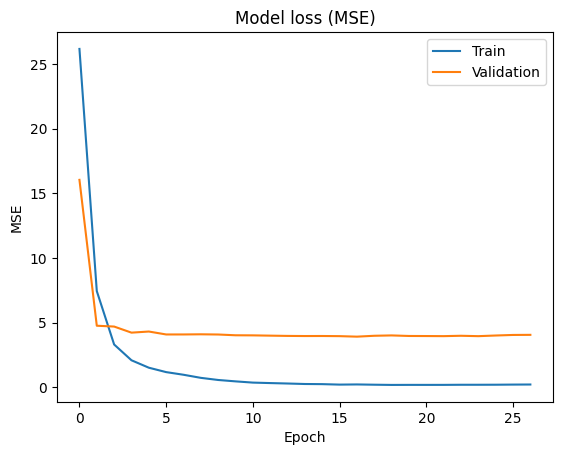

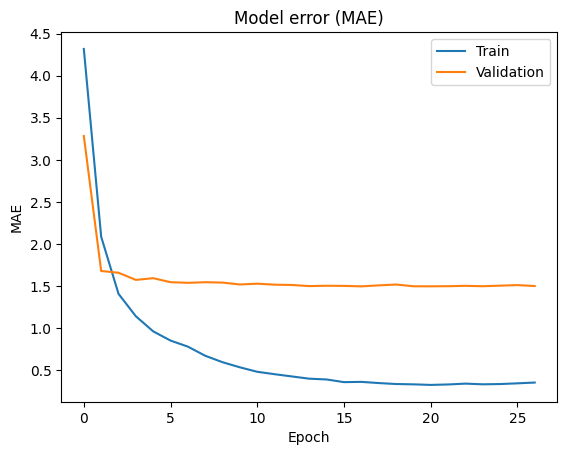

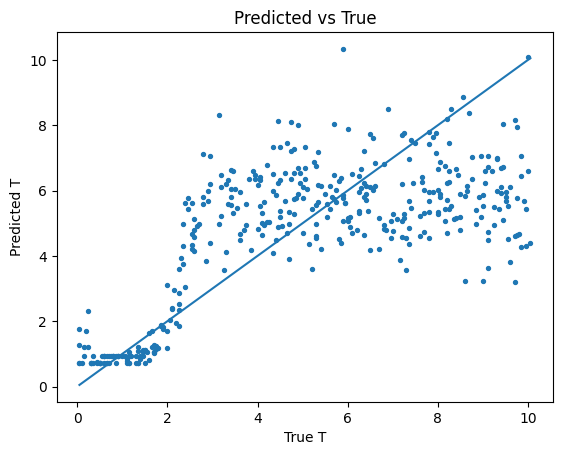

In [2]:
# --- Cell 1: Simple Dense Regression Neural Network (PyTorch Version) ---

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt

# ============================
# Device Setup
# ============================

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

# ============================
# Load and Prepare Data
# ============================

df = pd.read_csv("ising_states_cpp.csv")

X = df.drop(columns=["T"]).values.astype(np.float32)
y = df["T"].values.astype(np.float32).reshape(-1, 1)

scaler = StandardScaler()
X = scaler.fit_transform(X).astype(np.float32)

x_train, x_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Convert to tensors
x_train_t = torch.tensor(x_train).to(device)
x_test_t  = torch.tensor(x_test).to(device)
y_train_t = torch.tensor(y_train).to(device)
y_test_t  = torch.tensor(y_test).to(device)

# DataLoaders
batch_size = 64

train_loader = DataLoader(
    TensorDataset(x_train_t, y_train_t),
    batch_size=batch_size,
    shuffle=True
)

val_loader = DataLoader(
    TensorDataset(x_test_t, y_test_t),
    batch_size=batch_size
)

# ============================
# Dense Regression Model
# ============================

class DenseRegression(nn.Module):
    def __init__(self, input_dim):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(input_dim, 128),
            nn.ReLU(),
            nn.Dropout(0.1),
            nn.Linear(128, 64),
            nn.ReLU(),
            nn.Linear(64, 1)
        )

    def forward(self, x):
        return self.net(x)

model = DenseRegression(X.shape[1]).to(device)

# ============================
# Training Setup
# ============================

criterion = nn.MSELoss()
optimizer = optim.Adam(model.parameters(), weight_decay=1e-4)  # L2 regularization

epochs = 100
patience = 10
best_val = np.inf
patience_counter = 0

history = {
    "loss": [],
    "val_loss": [],
    "mae": [],
    "val_mae": []
}

# ============================
# Training Loop with Early Stopping
# ============================

for epoch in range(epochs):
    # ---- Training ----
    model.train()
    train_loss = 0
    train_mae = 0

    for xb, yb in train_loader:
        optimizer.zero_grad()
        preds = model(xb)
        loss = criterion(preds, yb)
        loss.backward()
        optimizer.step()

        train_loss += loss.item()
        train_mae += torch.mean(torch.abs(preds - yb)).item()

    train_loss /= len(train_loader)
    train_mae  /= len(train_loader)

    # ---- Validation ----
    model.eval()
    val_loss = 0
    val_mae = 0

    with torch.no_grad():
        for xb, yb in val_loader:
            preds = model(xb)
            val_loss += criterion(preds, yb).item()
            val_mae += torch.mean(torch.abs(preds - yb)).item()

    val_loss /= len(val_loader)
    val_mae  /= len(val_loader)

    history["loss"].append(train_loss)
    history["val_loss"].append(val_loss)
    history["mae"].append(train_mae)
    history["val_mae"].append(val_mae)

    print(
        f"Epoch {epoch+1:03d} | "
        f"Train MSE: {train_loss:.6f} | Val MSE: {val_loss:.6f} | "
        f"Train MAE: {train_mae:.6f} | Val MAE: {val_mae:.6f}"
    )

    # ---- Early Stopping ----
    if val_loss < best_val:
        best_val = val_loss
        best_weights = model.state_dict()
        patience_counter = 0
    else:
        patience_counter += 1
        if patience_counter >= patience:
            print("Early stopping triggered.")
            model.load_state_dict(best_weights)
            break

# ============================
# Final Evaluation
# ============================

model.eval()
with torch.no_grad():
    y_pred_test = model(x_test_t)
    test_mse = criterion(y_pred_test, y_test_t).item()
    test_mae = torch.mean(torch.abs(y_pred_test - y_test_t)).item()

print(f"\nTest MSE: {test_mse:.6f}")
print(f"Test MAE: {test_mae:.6f}")

# ============================
# Training Curves
# ============================

plt.figure()
plt.plot(history["loss"])
plt.plot(history["val_loss"])
plt.title("Model loss (MSE)")
plt.ylabel("MSE")
plt.xlabel("Epoch")
plt.legend(["Train", "Validation"], loc="upper right")
plt.show()

plt.figure()
plt.plot(history["mae"])
plt.plot(history["val_mae"])
plt.title("Model error (MAE)")
plt.ylabel("MAE")
plt.xlabel("Epoch")
plt.legend(["Train", "Validation"], loc="upper right")
plt.show()

# ============================
# Parity Plot
# ============================

model.eval()
with torch.no_grad():
    y_pred = model(x_test_t).cpu().numpy().flatten()

plt.figure()
plt.scatter(y_test.flatten(), y_pred, s=8)
plt.title("Predicted vs True")
plt.xlabel("True T")
plt.ylabel("Predicted T")
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()])
plt.show()



Training Dense Model

Epoch 001 | Val MSE: 11.723130 | Val MAE: 2.726233
Epoch 002 | Val MSE: 4.761030 | Val MAE: 1.712080
Epoch 003 | Val MSE: 4.573787 | Val MAE: 1.654664
Epoch 004 | Val MSE: 4.231835 | Val MAE: 1.590887
Epoch 005 | Val MSE: 4.148389 | Val MAE: 1.573778
Epoch 006 | Val MSE: 4.039410 | Val MAE: 1.546947
Epoch 007 | Val MSE: 4.040626 | Val MAE: 1.547459
Epoch 008 | Val MSE: 4.018902 | Val MAE: 1.532916
Epoch 009 | Val MSE: 3.914368 | Val MAE: 1.507091
Epoch 010 | Val MSE: 3.921363 | Val MAE: 1.500040
Epoch 011 | Val MSE: 3.902851 | Val MAE: 1.493546
Epoch 012 | Val MSE: 3.841517 | Val MAE: 1.481856
Epoch 013 | Val MSE: 3.838963 | Val MAE: 1.487973
Epoch 014 | Val MSE: 3.813794 | Val MAE: 1.475722
Epoch 015 | Val MSE: 3.792220 | Val MAE: 1.467553
Epoch 016 | Val MSE: 3.869149 | Val MAE: 1.491511
Epoch 017 | Val MSE: 3.790609 | Val MAE: 1.468308
Epoch 018 | Val MSE: 3.795416 | Val MAE: 1.465277
Epoch 019 | Val MSE: 3.726665 | Val MAE: 1.454107
Epoch 020 | Val MSE: 3.798

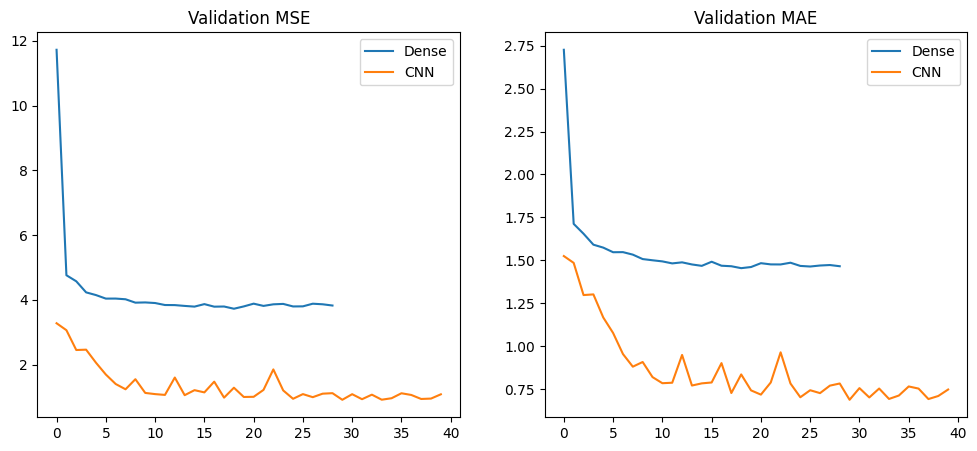

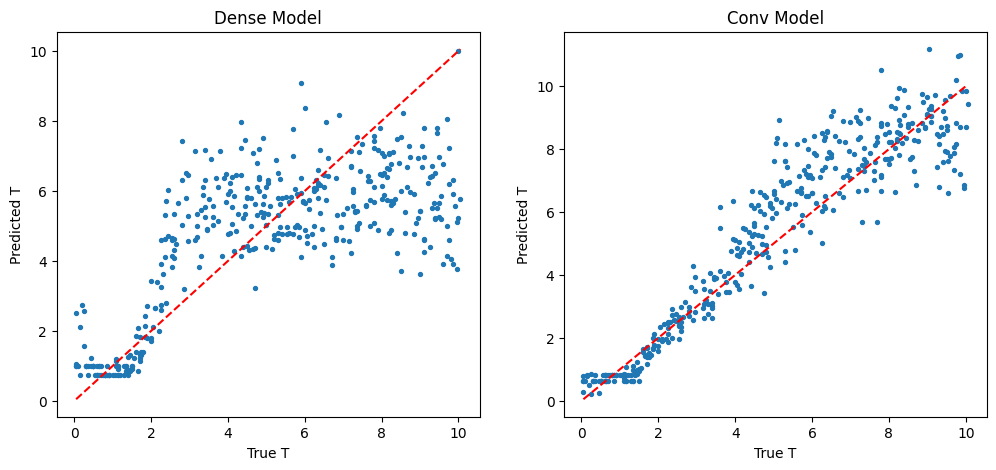

In [1]:
# --- Cell 2: Direct comparison between Dense and CNN using PyTorch ---

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt

# ============================
# Load and Clean Data
# ============================

df = pd.read_csv("ising_states_cpp.csv")

X = df.iloc[:, 2:].values.astype(np.float32)
y = df.iloc[:, 0].values.astype(np.float32).reshape(-1, 1)

# Infer lattice size
L = int(np.sqrt(X.shape[1]))
assert L * L == X.shape[1], "Feature count is not a perfect square."

# Normalize
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X).astype(np.float32)

# Train/Test Split
x_train, x_test, y_train, y_test = train_test_split(
    X_scaled, y, test_size=0.2, random_state=42
)

# CNN Reshape (N, C, H, W)
x_train_cnn = x_train.reshape(-1, 1, L, L)
x_test_cnn = x_test.reshape(-1, 1, L, L)

# Convert to tensors
x_train_t = torch.tensor(x_train)
x_test_t = torch.tensor(x_test)
x_train_cnn_t = torch.tensor(x_train_cnn)
x_test_cnn_t = torch.tensor(x_test_cnn)
y_train_t = torch.tensor(y_train)
y_test_t = torch.tensor(y_test)

# Datasets & Loaders
batch_size = 64

dense_train_loader = DataLoader(TensorDataset(x_train_t, y_train_t), batch_size=batch_size, shuffle=True)
dense_val_loader   = DataLoader(TensorDataset(x_test_t, y_test_t), batch_size=batch_size)

cnn_train_loader = DataLoader(TensorDataset(x_train_cnn_t, y_train_t), batch_size=batch_size, shuffle=True)
cnn_val_loader   = DataLoader(TensorDataset(x_test_cnn_t, y_test_t), batch_size=batch_size)

# ============================
# Dense Model
# ============================

class DenseModel(nn.Module):
    def __init__(self, input_dim):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(input_dim, 128),
            nn.ReLU(),
            nn.Dropout(0.1),
            nn.Linear(128, 64),
            nn.ReLU(),
            nn.Linear(64, 1)
        )

    def forward(self, x):
        return self.net(x)

# ============================
# CNN Model
# ============================

class ConvModel(nn.Module):
    def __init__(self):
        super().__init__()
        self.conv = nn.Sequential(
            nn.Conv2d(1, 32, 3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(32, 64, 3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(64, 128, 3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2)
        )

        with torch.no_grad():
            dummy = torch.zeros(1, 1, L, L)
            flat_size = self.conv(dummy).view(1, -1).shape[1]

        self.fc = nn.Sequential(
            nn.Linear(flat_size, 128),
            nn.ReLU(),
            nn.Dropout(0.1),
            nn.Linear(128, 1)
        )

    def forward(self, x):
        x = self.conv(x)
        x = x.view(x.size(0), -1)
        return self.fc(x)

# ============================
# Training Utilities
# ============================

def train_model(model, train_loader, val_loader, weight_decay=1.3e-4, epochs=100):
    criterion = nn.MSELoss()
    optimizer = optim.Adam(model.parameters(), weight_decay=weight_decay)

    best_val = np.inf
    patience, patience_counter = 10, 0

    history = {"val_loss": [], "val_mae": []}

    for epoch in range(epochs):
        model.train()
        for xb, yb in train_loader:
            optimizer.zero_grad()
            pred = model(xb)
            loss = criterion(pred, yb)
            loss.backward()
            optimizer.step()

        # Validation
        model.eval()
        val_loss = 0
        val_mae = 0
        with torch.no_grad():
            for xb, yb in val_loader:
                pred = model(xb)
                val_loss += criterion(pred, yb).item()
                val_mae += torch.mean(torch.abs(pred - yb)).item()

        val_loss /= len(val_loader)
        val_mae /= len(val_loader)

        history["val_loss"].append(val_loss)
        history["val_mae"].append(val_mae)

        print(f"Epoch {epoch+1:03d} | Val MSE: {val_loss:.6f} | Val MAE: {val_mae:.6f}")

        # Early Stopping
        if val_loss < best_val:
            best_val = val_loss
            best_weights = model.state_dict()
            patience_counter = 0
        else:
            patience_counter += 1
            if patience_counter >= patience:
                print("Early stopping triggered.")
                model.load_state_dict(best_weights)
                break

    return history

# ============================
# Train Both Models
# ============================

dense_model = DenseModel(X.shape[1])
conv_model  = ConvModel()

print("\nTraining Dense Model\n")
history_dense = train_model(dense_model, dense_train_loader, dense_val_loader)

print("\nTraining CNN Model\n")
history_conv = train_model(conv_model, cnn_train_loader, cnn_val_loader)

# ============================
# Evaluation
# ============================

def evaluate(model, loader):
    model.eval()
    mse, mae = 0, 0
    with torch.no_grad():
        for xb, yb in loader:
            pred = model(xb)
            mse += nn.MSELoss()(pred, yb).item()
            mae += torch.mean(torch.abs(pred - yb)).item()
    return mse / len(loader), mae / len(loader)

test_loss_dense, test_mae_dense = evaluate(dense_model, dense_val_loader)
test_loss_conv,  test_mae_conv  = evaluate(conv_model, cnn_val_loader)

print(f"\nDense Model → Test MSE: {test_loss_dense:.6f}, MAE: {test_mae_dense:.6f}")
print(f"Conv Model  → Test MSE: {test_loss_conv:.6f}, MAE: {test_mae_conv:.6f}")

# ============================
# Training Curves
# ============================

plt.figure(figsize=(12,5))

plt.subplot(1,2,1)
plt.plot(history_dense["val_loss"], label="Dense")
plt.plot(history_conv["val_loss"], label="CNN")
plt.title("Validation MSE")
plt.legend()

plt.subplot(1,2,2)
plt.plot(history_dense["val_mae"], label="Dense")
plt.plot(history_conv["val_mae"], label="CNN")
plt.title("Validation MAE")
plt.legend()

plt.show()

# ============================
# Parity Plots
# ============================

dense_model.eval()
conv_model.eval()

with torch.no_grad():
    y_pred_dense = dense_model(x_test_t).numpy().flatten()
    y_pred_conv  = conv_model(x_test_cnn_t).numpy().flatten()

plt.figure(figsize=(12,5))

plt.subplot(1,2,1)
plt.scatter(y_test, y_pred_dense, s=8)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], "r--")
plt.title("Dense Model")
plt.xlabel("True T")
plt.ylabel("Predicted T")

plt.subplot(1,2,2)
plt.scatter(y_test, y_pred_conv, s=8)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], "r--")
plt.title("Conv Model")
plt.xlabel("True T")
plt.ylabel("Predicted T")

plt.show()



=== Test Metrics Comparison ===
Model  Test Huber  Test MAE  Test MSE
Dense    1.183779  1.589031  4.400860
  CNN    0.447373  0.804885  1.207361


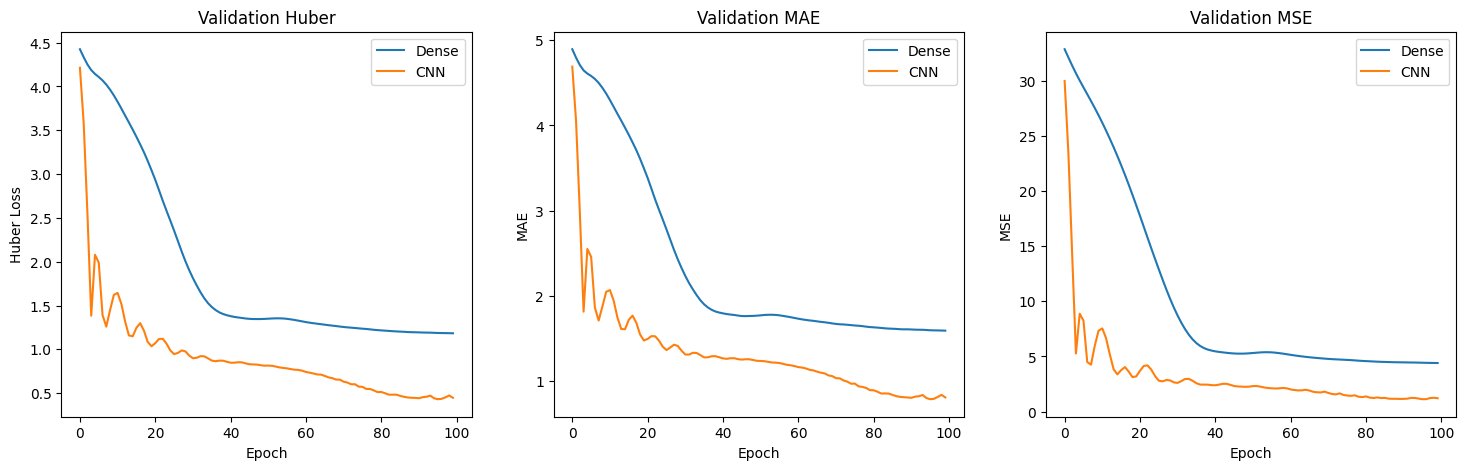

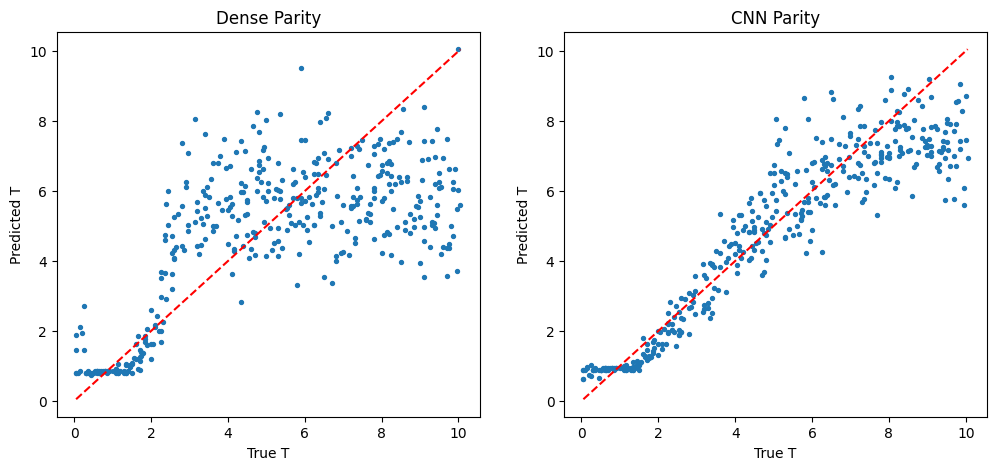

In [2]:
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.optim as optim
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt

# =========================
# Load Data
# =========================
df = pd.read_csv("ising_states_cpp.csv")

y = df.iloc[:, 0].values.astype(np.float32).reshape(-1, 1)
magnetization = df.iloc[:, 1].values.astype(np.float32).reshape(-1, 1)
spins = df.iloc[:, 2:].values.astype(np.float32)

# =========================
# Normalize Spins
# =========================
scaler = StandardScaler()
spins_scaled = scaler.fit_transform(spins).astype(np.float32)

# =========================
# Train/Test Split
# =========================
x_train_spins, x_test_spins, y_train, y_test, x_train_mag, x_test_mag = train_test_split(
    spins_scaled, y, magnetization, test_size=0.2, random_state=42
)

# =========================
# CNN Reshape
# =========================
L = int(np.sqrt(spins_scaled.shape[1]))

x_train_spins_cnn = x_train_spins.reshape(-1, 1, L, L)
x_test_spins_cnn  = x_test_spins.reshape(-1, 1, L, L)

# =========================
# Convert to Torch Tensors
# =========================
device = "cuda" if torch.cuda.is_available() else "cpu"

X_dense_train = torch.tensor(np.hstack([x_train_mag, x_train_spins]), dtype=torch.float32).to(device)
X_dense_test  = torch.tensor(np.hstack([x_test_mag, x_test_spins]), dtype=torch.float32).to(device)

X_cnn_train   = torch.tensor(x_train_spins_cnn, dtype=torch.float32).to(device)
X_cnn_test    = torch.tensor(x_test_spins_cnn, dtype=torch.float32).to(device)

M_train = torch.tensor(x_train_mag, dtype=torch.float32).to(device)
M_test  = torch.tensor(x_test_mag, dtype=torch.float32).to(device)

y_train = torch.tensor(y_train, dtype=torch.float32).to(device)
y_test  = torch.tensor(y_test, dtype=torch.float32).to(device)

# =========================
# Dense Model (MLP)
# =========================
class DenseModel(nn.Module):
    def __init__(self, n_features):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(n_features, 128),
            nn.ReLU(),
            nn.Dropout(0.1),
            nn.Linear(128, 64),
            nn.ReLU(),
            nn.Linear(64, 1)
        )

    def forward(self, x):
        return self.net(x)

# =========================
# CNN + Magnetization Model
# =========================
class CNNModel(nn.Module):
    def __init__(self):
        super().__init__()
        self.cnn = nn.Sequential(
            nn.Conv2d(1, 32, 3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(32, 64, 3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(64, 128, 3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2)
        )

        self.flat_dim = 128 * (L//8) * (L//8)

        self.fc = nn.Sequential(
            nn.Linear(self.flat_dim + 1, 128),
            nn.ReLU(),
            nn.Dropout(0.1),
            nn.Linear(128, 1)
        )

    def forward(self, x, m):
        x = self.cnn(x)
        x = x.view(x.shape[0], -1)
        x = torch.cat([x, m], dim=1)
        return self.fc(x)

# =========================
# Training Utility (Huber + MAE + MSE)
# =========================
def train_model(model, optimizer, X, y, X_val, y_val, extra_input=None, extra_val=None):
    huber_fn = nn.SmoothL1Loss(beta=1.0)
    mae_fn   = nn.L1Loss()
    mse_fn   = nn.MSELoss()

    best_loss = np.inf
    patience, wait = 10, 0

    history = {
        "val_huber": [],
        "val_mae": [],
        "val_mse": []
    }

    for epoch in range(100):
        model.train()
        optimizer.zero_grad()

        if extra_input is None:
            y_pred = model(X)
        else:
            y_pred = model(X, extra_input)

        loss = huber_fn(y_pred, y)   # train on Huber
        loss.backward()
        optimizer.step()

        model.eval()
        with torch.no_grad():
            if extra_val is None:
                val_pred = model(X_val)
            else:
                val_pred = model(X_val, extra_val)

            val_huber = huber_fn(val_pred, y_val).item()
            val_mae   = mae_fn(val_pred, y_val).item()
            val_mse   = mse_fn(val_pred, y_val).item()

        history["val_huber"].append(val_huber)
        history["val_mae"].append(val_mae)
        history["val_mse"].append(val_mse)

        # Early stopping based on Huber
        if val_huber < best_loss:
            best_loss = val_huber
            best_state = model.state_dict()
            wait = 0
        else:
            wait += 1
            if wait >= patience:
                break

    model.load_state_dict(best_state)
    return history

# =========================
# Train Models
# =========================
dense_model = DenseModel(X_dense_train.shape[1]).to(device)
cnn_model   = CNNModel().to(device)

opt_dense = optim.Adam(dense_model.parameters(), lr=1e-3, weight_decay=1.3e-4)
opt_cnn   = optim.Adam(cnn_model.parameters(), lr=1e-3, weight_decay=1e-4)

history_dense = train_model(
    dense_model, opt_dense,
    X_dense_train, y_train,
    X_dense_test, y_test
)

history_cnn = train_model(
    cnn_model, opt_cnn,
    X_cnn_train, y_train,
    X_cnn_test, y_test,
    M_train, M_test
)

# =========================
# Evaluation (Huber + MAE + MSE)
# =========================
dense_model.eval()
cnn_model.eval()

huber_fn = nn.SmoothL1Loss(beta=1.0)
mae_fn   = nn.L1Loss()
mse_fn   = nn.MSELoss()

with torch.no_grad():
    y_pred_dense_t = dense_model(X_dense_test)
    y_pred_cnn_t   = cnn_model(X_cnn_test, M_test)

dense_huber = huber_fn(y_pred_dense_t, y_test).item()
dense_mae   = mae_fn(y_pred_dense_t, y_test).item()
dense_mse   = mse_fn(y_pred_dense_t, y_test).item()

cnn_huber = huber_fn(y_pred_cnn_t, y_test).item()
cnn_mae   = mae_fn(y_pred_cnn_t, y_test).item()
cnn_mse   = mse_fn(y_pred_cnn_t, y_test).item()

# =========================
# Pretty Table Output
# =========================
results = pd.DataFrame([
    {"Model": "Dense", "Test Huber": dense_huber, "Test MAE": dense_mae, "Test MSE": dense_mse},
    {"Model": "CNN",   "Test Huber": cnn_huber,   "Test MAE": cnn_mae,   "Test MSE": cnn_mse},
])

# nicer formatting
print("\n=== Test Metrics Comparison ===")
print(results.to_string(index=False, float_format=lambda x: f"{x:.6f}"))

# Convert to numpy for parity plot
y_pred_dense = y_pred_dense_t.cpu().numpy().flatten()
y_pred_cnn   = y_pred_cnn_t.cpu().numpy().flatten()
y_true       = y_test.cpu().numpy().flatten()

# =========================
# Validation Curves (Huber + MAE + MSE)
# =========================
plt.figure(figsize=(18,5))

plt.subplot(1,3,1)
plt.plot(history_dense['val_huber'], label="Dense")
plt.plot(history_cnn['val_huber'], label="CNN")
plt.xlabel("Epoch")
plt.ylabel("Huber Loss")
plt.title("Validation Huber")
plt.legend()

plt.subplot(1,3,2)
plt.plot(history_dense['val_mae'], label="Dense")
plt.plot(history_cnn['val_mae'], label="CNN")
plt.xlabel("Epoch")
plt.ylabel("MAE")
plt.title("Validation MAE")
plt.legend()

plt.subplot(1,3,3)
plt.plot(history_dense['val_mse'], label="Dense")
plt.plot(history_cnn['val_mse'], label="CNN")
plt.xlabel("Epoch")
plt.ylabel("MSE")
plt.title("Validation MSE")
plt.legend()

plt.show()

# =========================
# Parity Plots
# =========================
plt.figure(figsize=(12,5))

plt.subplot(1,2,1)
plt.scatter(y_true, y_pred_dense, s=8)
plt.plot([y_true.min(), y_true.max()], [y_true.min(), y_true.max()], 'r--')
plt.title("Dense Parity")
plt.xlabel("True T")
plt.ylabel("Predicted T")

plt.subplot(1,2,2)
plt.scatter(y_true, y_pred_cnn, s=8)
plt.plot([y_true.min(), y_true.max()], [y_true.min(), y_true.max()], 'r--')
plt.title("CNN Parity")
plt.xlabel("True T")
plt.ylabel("Predicted T")

plt.show()
